# Workshop 3 - Data quality findings in the Silver layer

This notebook measures the quality of the Silver layer (`datalake_silver/<topic>/`) with pandas. Its findings justify the governance indicators that `src/volcano_pipeline/gold/governance.py` computes with PySpark. Three kinds of items are kept apart:

* **Data-quality KPIs** (6): measure the data itself and have a target.
* **Operational metrics** (3): measure how the pipeline delivers the data (volume, timing).
* **Descriptive findings**: observations and processing decisions. They are documented and linked to the indicator that monitors them, but are not indicators themselves.

| Indicator | Type | Dimension (DAMA-DMBOK) | Breakdowns in Gold (`dimension`) | Section |
|---|---|---|---|---|
| `null_rate` | quality KPI | Completeness | `topic.column` | 3 |
| `duplicate_rate` | quality KPI | Uniqueness | after dedup (Silver: exact copies, same-value copies, real revisions) and before dedup (Bronze FDSN) | 4 |
| `schema_compliance` | quality KPI | Validity (structure) | topic | 5.1 |
| `quarantine_rate` | quality KPI | Validity (business rules) | source; reason and category as breakdown | 5.2 |
| `outlier_rate` | quality KPI | Accuracy / plausibility | field; per-volcano fences over all records | 6 |
| `text_length` | quality KPI | Consistency | observatory, year; encoding-error rate as sub-metric | 7 |
| `volume` | operational metric | - | topic, week | 2 |
| `freshness` | operational metric | Timeliness | source | 8 |
| `ingestion_frequency` | operational metric | Timeliness | source, day | 8 |
| ~~`language_distribution`~~ | excluded | - | single-language corpus, see 7.3 | 7.3 |

Section 9 links every finding to the indicator that monitors it.

Run it from the repository root or from `notebooks/` after the Bronze backfills and at least one `silver_processing` run. Every number is computed from the data, so re-running the notebook refreshes the findings. Figures are saved to `workshop_3/figures/dq_*.png` for the report.

## 1. Setup and loading

In [1]:
from pathlib import Path
import re
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
import yaml

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

ROOT = Path.cwd() if (Path.cwd() / "datalake_silver").exists() else Path.cwd().parent
SILVER, BRONZE = ROOT / "datalake_silver", ROOT / "datalake_bronze"
FIG = ROOT / "workshop_3" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

TOPICS = ["volcanoes", "eruptions", "earthquakes", "alert_notices", "notices", "volcano_updates"]
LINEAGE = ["bronze_file", "bronze_sha256", "processed_utc"]
BRONZE_NAME = re.compile(r"^(?P<source>.+)_(?P<stamp>\d{8}_\d{6})\.json$")
MEASURED_AT = pd.Timestamp.now(tz="UTC")


def read_topic(topic: str) -> pd.DataFrame:
    # every Parquet file of the topic folder as one DataFrame (empty if the topic has no file yet)
    folder = SILVER / topic
    if not any(folder.glob("*.parquet")):
        return pd.DataFrame()
    return pd.read_parquet(folder)


def latest(df: pd.DataFrame) -> pd.DataFrame:
    # newest version of each record_id: Silver writes a record again when it changes at the source
    if df.empty:
        return df
    return df.sort_values("processed_utc").drop_duplicates("record_id", keep="last")


def source_of(bronze_file: pd.Series) -> pd.Series:
    # Bronze source id from the lineage column, e.g. usgs_feed_20261117_013256.json -> usgs_feed
    return bronze_file.str.extract(BRONZE_NAME)["source"]


def save(fig, name: str):
    fig.tight_layout()
    fig.savefig(FIG / f"dq_{name}.png", dpi=150)


silver = {t: read_topic(t) for t in TOPICS}
quarantine = read_topic("quarantine")
current = {t: latest(df) for t, df in silver.items()}

print(f"Measured at {MEASURED_AT:%Y-%m-%d %H:%M} UTC from {SILVER}")
{t: df.shape for t, df in {**silver, "quarantine": quarantine}.items()}

Measured at 2026-11-19 23:28 UTC from /home/julianp/Documentos/semestre_8/dataAnalysis/project/Proyecto_Analisis_De_Datos/datalake_silver


{'volcanoes': (165, 13),
 'eruptions': (1281, 15),
 'earthquakes': (292264, 22),
 'alert_notices': (56, 16),
 'notices': (16537, 33),
 'volcano_updates': (12, 25),
 'quarantine': (2108, 5)}

## 2. Overview

Rows are every version written to Silver; `distinct_ids` are real-world records (one per `record_id`). The time column differs per topic.

In [2]:
TIME_COL = {"eruptions": "start_time", "earthquakes": "event_time", "alert_notices": "sent_time",
            "notices": "sent_time", "volcano_updates": "as_of_time", "volcanoes": None}

rows = []
for t, df in silver.items():
    tc = TIME_COL[t]
    rows.append({
        "topic": t,
        "rows": len(df),
        "distinct_ids": df["record_id"].nunique() if len(df) else 0,
        "columns": df.shape[1],
        "silver_files": len(list((SILVER / t).glob("*.parquet"))),
        "time_column": tc or "-",
        "from": df[tc].min() if tc and len(df) else None,
        "to": df[tc].max() if tc and len(df) else None,
    })
rows.append({"topic": "quarantine", "rows": len(quarantine), "distinct_ids": None, "columns": quarantine.shape[1],
             "silver_files": len(list((SILVER / "quarantine").glob("*.parquet"))), "time_column": "processed_utc",
             "from": quarantine["processed_utc"].min() if len(quarantine) else None,
             "to": quarantine["processed_utc"].max() if len(quarantine) else None})
overview = pd.DataFrame(rows).set_index("topic").astype({"distinct_ids": "Int64"})
overview

,rows,distinct_ids,columns,silver_files,time_column,from,to
topic,,,,,,,
volcanoes,165,165,13,1,-,NaT,NaT
eruptions,1281,1281,15,1,start_time,0010-01-01 00:00:00.000000+00:00,2025-10-20 00:00:00.000000+00:00
earthquakes,292264,291595,22,4,event_time,2010-01-01 03:35:15.900000+00:00,2026-11-19 22:29:11.180000+00:00
alert_notices,56,56,16,3,sent_time,2009-11-18 16:05:08.000000+00:00,2026-11-19 22:47:09.000000+00:00
notices,16537,16537,33,3,sent_time,2010-01-01 18:25:34.000000+00:00,2026-11-19 22:47:09.000000+00:00
volcano_updates,12,12,25,2,as_of_time,2026-11-02 16:09:00.000000+00:00,2026-11-19 18:37:16.000000+00:00
quarantine,2108,<NA>,5,3,processed_utc,2026-11-17 01:33:25.576025+00:00,2026-11-19 22:51:47.669841+00:00


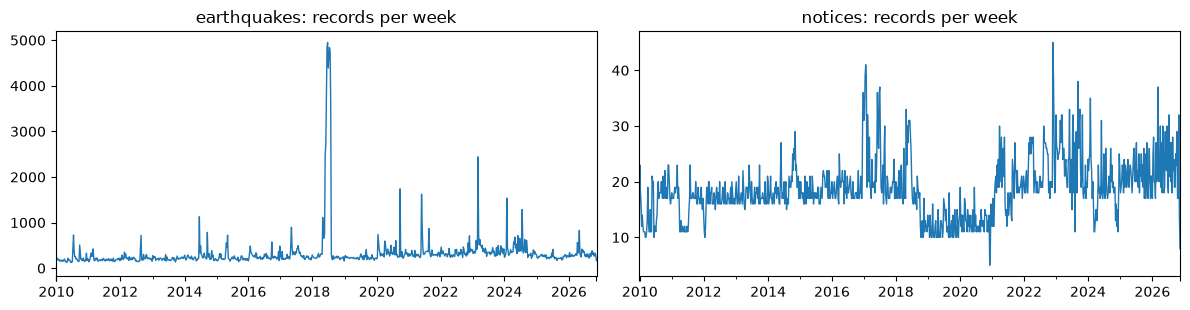

In [3]:
# Records per week (newest version, by the topic's own time column) - operational metric `volume`
weekly = {}
for t in ["earthquakes", "notices"]:
    df = current[t]
    if len(df):
        weekly[t] = df.set_index(TIME_COL[t]).resample("W-MON", label="left", closed="left").size()

fig, axes = plt.subplots(1, len(weekly), figsize=(12, 3.2), squeeze=False)
for ax, (t, s) in zip(axes[0], weekly.items()):
    s.plot(ax=ax, lw=1)
    ax.set_title(f"{t}: records per week")
    ax.set_xlabel("")
save(fig, "volume_weekly")

## 3. Completeness

A value counts as missing when it is null, an empty or blank string, or an empty list (`tokens`). Rates are computed on the newest version of each record, so a record revised three times is not counted three times.

In [4]:
def missing_mask(s: pd.Series) -> pd.Series:
    mask = s.isna().to_numpy()
    sample = s.dropna()
    if sample.empty:
        return pd.Series(mask, index=s.index)
    first = sample.iloc[0]
    if isinstance(first, str):
        blank = s.astype("string").str.strip().eq("").fillna(False).to_numpy(dtype=bool)
        mask = mask | blank
    elif hasattr(first, "__len__"):   # list columns come back as numpy arrays
        empty = s.map(lambda v: v is not None and not isinstance(v, str) and hasattr(v, "__len__") and len(v) == 0)
        mask = mask | empty.to_numpy(dtype=bool)
    return pd.Series(mask, index=s.index)


null_rows = []
for t, df in current.items():
    for c in df.columns:
        m = missing_mask(df[c])
        null_rows.append({"topic": t, "column": c, "field": f"{t}.{c}", "missing": int(m.sum()),
                          "records": len(df), "pct_missing": 100 * m.mean() if len(df) else 0.0})
null_rate = pd.DataFrame(null_rows)

# lineage columns must never be empty: any value here is a pipeline bug
lineage_gaps = null_rate[null_rate.column.isin(LINEAGE) & (null_rate.missing > 0)]
print("Lineage columns with gaps:", "none" if lineage_gaps.empty else lineage_gaps.field.tolist())

with_gaps = null_rate[null_rate.missing > 0].sort_values("pct_missing", ascending=False)
print(f"{len(with_gaps)} of {len(null_rate)} fields have missing values")
with_gaps.head(25)

Lineage columns with gaps: none
21 of 124 fields have missing values


,topic,column,field,missing,records,pct_missing
109,volcano_updates,notice_number,volcano_updates.notice_number,11,12,91.666667
110,volcano_updates,notice_url,volcano_updates.notice_url,8,12,66.666667
104,volcano_updates,vnum,volcano_updates.vnum,7,12,58.333333
20,eruptions,vei,eruptions.vei,480,1281,37.470726
108,volcano_updates,issued_raw,volcano_updates.issued_raw,4,12,33.333333
17,eruptions,start_time,eruptions.start_time,387,1281,30.210773
6,volcanoes,last_eruption_year,volcanoes.last_eruption_year,44,165,26.666667
103,volcano_updates,volcano_name,volcano_updates.volcano_name,2,12,16.666667
76,notices,region,notices.region,1886,16537,11.404729
75,notices,volcano_name,notices.volcano_name,1886,16537,11.404729


In [5]:
# Known causes of the main gaps (documented in workshop_2/preprocessing.md and the Part 1 hand-off)
KNOWN_CAUSE = {
    "eruptions.vei": "GVP has no VEI for the eruption; flag vei_missing, not imputed",
    "notices.alert_level": "VONA notices carry only the aviation colour code",
    "notices.alert_level_ord": "follows notices.alert_level",
    "notices.region": "region-wide notices have no single volcano",
    "notices.vnum": "region-wide or multi-volcano notices (vnums holds the list)",
    "notices.volcano_name": "region-wide notices",
    "alert_notices.latitude": "HANS notice without coordinates (flag coords_missing)",
    "alert_notices.longitude": "HANS notice without coordinates (flag coords_missing)",
    "earthquakes.mag": "event without magnitude (flag mag_missing)",
    "eruptions.start_time": "eruptions before year 1 / BCE (start_year keeps the year)",
}
with_gaps.assign(cause=with_gaps.field.map(KNOWN_CAUSE).fillna("")).head(25)[
    ["field", "missing", "records", "pct_missing", "cause"]]

,field,missing,records,pct_missing,cause
109,volcano_updates.notice_number,11,12,91.666667,
110,volcano_updates.notice_url,8,12,66.666667,
104,volcano_updates.vnum,7,12,58.333333,
20,eruptions.vei,480,1281,37.470726,GVP has no VEI for the eruption; flag vei_miss...
108,volcano_updates.issued_raw,4,12,33.333333,
17,eruptions.start_time,387,1281,30.210773,eruptions before year 1 / BCE (start_year keep...
6,volcanoes.last_eruption_year,44,165,26.666667,
103,volcano_updates.volcano_name,2,12,16.666667,
76,notices.region,1886,16537,11.404729,region-wide notices have no single volcano
75,notices.volcano_name,1886,16537,11.404729,region-wide notices


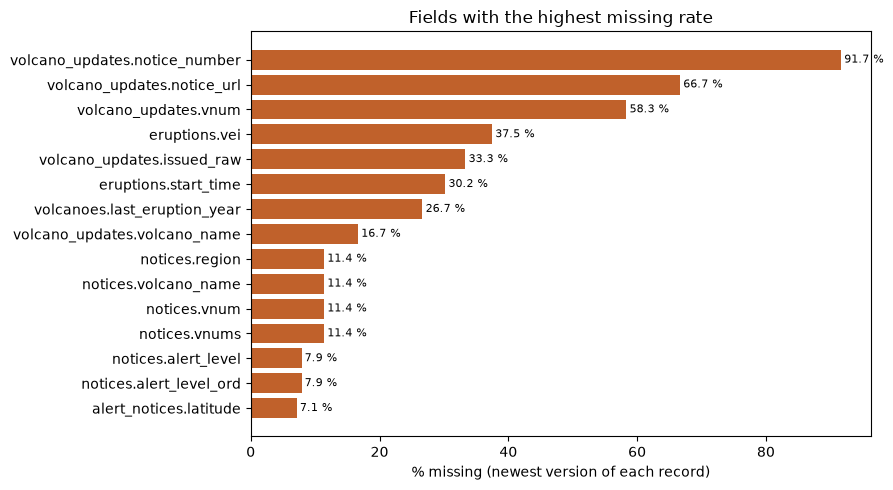

In [6]:
top = with_gaps[~with_gaps.column.isin(LINEAGE)].head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top.field, top.pct_missing, color="#c0612b")
ax.set_xlabel("% missing (newest version of each record)")
ax.set_title("Fields with the highest missing rate")
for y, v in enumerate(top.pct_missing):
    ax.text(v + 0.5, y, f"{v:.1f} %", va="center", fontsize=8)
save(fig, "null_rate")

## 4. Uniqueness

Silver is meant to drop copies before writing (dedup index in `_state/seen_<topic>.parquet`) and to keep a new **version** only when a record changes at the source (e.g. USGS revises a magnitude). The extra rows of a `record_id` are split in three classes:

* **exact copy**: same `record_id` and same `content_hash` (should be 0; otherwise the dedup let it through);
* **same-value copy**: same `record_id` and identical values, but another `content_hash` (the hash changed although nothing in the record did);
* **real revision**: same `record_id` with at least one value changed (legitimate; Gold keeps the newest with `latest()`).

"Values" are all columns except the key, the hash, the lineage columns and the per-batch outlier flags.

In [7]:
SKIP = {"record_id", "content_hash", "bronze_file", "bronze_sha256", "processed_utc"}

def value_hash(df: pd.DataFrame) -> pd.Series:
    cols = [c for c in df.columns if c not in SKIP and not c.startswith("is_outlier_")]
    as_text = df[cols].apply(lambda s: s.map(lambda v: str(list(v)) if hasattr(v, "__len__") and not isinstance(v, str) else str(v)))
    return pd.util.hash_pandas_object(as_text, index=False)

uniq_rows = []
for t, df in silver.items():
    if df.empty:
        continue
    n, ids = len(df), df["record_id"].nunique()
    pairs = len(df[["record_id", "content_hash"]].drop_duplicates())
    versions = len(pd.DataFrame({"r": df["record_id"].to_numpy(), "h": value_hash(df).to_numpy()}).drop_duplicates())
    uniq_rows.append({"topic": t, "rows": n, "distinct_ids": ids, "extra_rows": n - ids,
                      "exact_copies": n - pairs, "same_value_copies": n - versions, "real_revisions": versions - ids,
                      "pct_exact_copies": 100 * (n - pairs) / n, "pct_same_value_copies": 100 * (n - versions) / n,
                      "pct_real_revisions": 100 * (versions - ids) / n,
                      "max_rows_per_id": int(df["record_id"].value_counts().max())})
uniqueness = pd.DataFrame(uniq_rows).set_index("topic")
uniqueness

,rows,distinct_ids,extra_rows,exact_copies,same_value_copies,real_revisions,pct_exact_copies,pct_same_value_copies,pct_real_revisions,max_rows_per_id
topic,,,,,,,,,,
volcanoes,165,165,0,0,0,0,0.000000,0.00000,0.000000,1
eruptions,1281,1281,0,0,0,0,0.000000,0.00000,0.000000,1
earthquakes,292264,291595,669,278,649,20,0.095119,0.22206,0.006843,4
alert_notices,56,56,0,0,0,0,0.000000,0.00000,0.000000,1
notices,16537,16537,0,0,0,0,0.000000,0.00000,0.000000,1
volcano_updates,12,12,0,0,0,0,0.000000,0.00000,0.000000,1


### 4.0 Where the copies come from

The same earthquake arrives from two sources: the real-time feed (`usgs_feed`) and the FDSN service (`usgs_fdsn`). Both carry the same values, but their `content_hash` differs because the hash is computed on the source payload, whose format differs. The dedup index keeps only the **last** hash of each id, so when the feed sends the event again (it repeats its 7-day window every hour) after FDSN, Silver sees a "change" and writes it again: feed -> FDSN -> feed. The table shows the source sequence of the earthquakes with an exact copy.

In [8]:
eq_rows = silver["earthquakes"].assign(source=source_of(silver["earthquakes"]["bronze_file"]))
copied = eq_rows[eq_rows.duplicated(["record_id", "content_hash"], keep=False)]["record_id"].unique()
sequence = (eq_rows[eq_rows.record_id.isin(copied)].sort_values(["record_id", "processed_utc"])
            .groupby("record_id")["source"].agg(" -> ".join))
print(f"{len(copied)} earthquakes have an exact copy")
sequence.value_counts().rename("earthquakes").to_frame()

278 earthquakes have an exact copy


,earthquakes
source,
usgs_feed -> usgs_fdsn -> usgs_feed,260
usgs_feed -> usgs_feed -> usgs_fdsn -> usgs_feed,18


In [9]:
# HANS notices: one identifier can be published twice, as an activity notice (VAN) and as its
# aviation version (VONA, notice type VV). The Silver key is identifier + notice type, so both are kept.
n = current["notices"]
shared = pd.Series(dtype=int)
if len(n):
    per_id = n.groupby("notice_identifier")["notice_type"].nunique()
    shared = per_id[per_id > 1]
    print(f"{len(shared)} notice identifiers appear with more than one notice type")
    display(n[n.notice_identifier.isin(shared.index)].groupby("notice_identifier")["notice_type"]
            .apply(lambda s: "/".join(sorted(map(str, s)))).value_counts().rename("identifiers"))

706 notice identifiers appear with more than one notice type


notice_type
VAN/VV    706
Name: identifiers, dtype: int64

### 4.1 Before deduplication: the Bronze to Silver funnel

Silver shows no exact copies because duplicates are removed **before** writing (dedup index in `_state/seen_<topic>.parquet`). To see that step, compare the records each Bronze file brought (`record_count` in its envelope) with what reached Silver or the quarantine. The difference mixes two causes that Silver does not log separately: records already seen (duplicates) and records out of scope (earthquakes more than 30 km from any volcano). Files that added no row at all were fully absorbed.

In [10]:
import json
COUNT = re.compile(r'"record_count":\s*(\d+)')

def record_count(path: Path) -> int:
    # record_count is written before the payload in the envelope, so the file head is enough
    with path.open("r", encoding="utf-8") as fh:
        m = COUNT.search(fh.read(8192))
    return int(m.group(1)) if m else 0

# only Bronze files that Silver already processed (listed in its manifest); newer files are still pending
processed_files = set(json.loads((SILVER / "_state" / "manifest.json").read_text()))
bronze_files = pd.DataFrame({"file": sorted(p.name for p in BRONZE.glob("*.json") if p.name in processed_files)})
bronze_files["source"] = source_of(bronze_files.file)
bronze_files["bronze_records"] = [record_count(BRONZE / f) for f in bronze_files.file]

landed = pd.concat([df[["bronze_file"]] for df in [*silver.values(), quarantine] if len(df)])
landed = landed.bronze_file.value_counts()
bronze_files["landed"] = bronze_files.file.map(landed).fillna(0).astype(int)

funnel = bronze_files.groupby("source").agg(
    files=("file", "size"), files_without_rows=("landed", lambda s: int((s == 0).sum())),
    bronze_records=("bronze_records", "sum"), landed_in_silver_or_quarantine=("landed", "sum"))
funnel["dropped_dup_or_out_of_scope"] = funnel.bronze_records - funnel.landed_in_silver_or_quarantine
funnel["pct_dropped"] = 100 * funnel.dropped_dup_or_out_of_scope / funnel.bronze_records.where(funnel.bronze_records > 0)
funnel.sort_values("bronze_records", ascending=False)

,files,files_without_rows,bronze_records,landed_in_silver_or_quarantine,dropped_dup_or_out_of_scope,pct_dropped
source,,,,,,
usgs_fdsn,169,4,368464,293533,74931,20.336044
usgs_hans_notices,206,2,16626,16541,85,0.511247
gvp_eruptions,1,0,11089,1281,9808,88.448012
usgs_feed,4,1,7298,820,6478,88.764045
usgs_hans,3,0,207,71,136,65.700483
usgs_hans_volcanoes,1,1,170,0,170,100.000000
gvp_volcanoes,1,0,165,165,0,0.000000
usgs_volcano_updates,2,0,18,12,6,33.333333


Most of the gap is scope, not duplication: GVP returns the whole world (Silver keeps the United States), the USGS feed is worldwide (Silver keeps events within 30 km of a US volcano) and `usgs_hans_volcanoes` is a reference list, not data. FDSN is the exception: it is queried volcano by volcano with a 30 km radius, so the circles of neighbouring volcanoes overlap. The cell below checks how many FDSN records are the same event returned twice.

In [11]:
import json
fdsn_ids = Counter()
for path in BRONZE.glob("usgs_fdsn_*.json"):
    if path.name not in processed_files:   # same files as the funnel above
        continue
    payload = json.loads(path.read_text(encoding="utf-8"))["payload"]
    feats = payload.get("features", []) if isinstance(payload, dict) else payload
    fdsn_ids.update(f.get("id") for f in feats)
fdsn_total, fdsn_distinct = sum(fdsn_ids.values()), len(fdsn_ids)
fdsn_repeated = fdsn_total - fdsn_distinct
fdsn_dropped = int(funnel.loc["usgs_fdsn", "dropped_dup_or_out_of_scope"]) if "usgs_fdsn" in funnel.index else 0
print(f"FDSN Bronze: {fdsn_total:,} records, {fdsn_distinct:,} distinct events, {fdsn_repeated:,} repeated "
      f"({100 * fdsn_repeated / max(1, fdsn_total):.1f} % of the records; "
      f"{100 * fdsn_repeated / max(1, fdsn_dropped):.0f} % of the FDSN records dropped before Silver)")
print("Most repeated event appears", max(fdsn_ids.values(), default=0), "times")

FDSN Bronze: 368,464 records, 295,550 distinct events, 72,914 repeated (19.8 % of the records; 97 % of the FDSN records dropped before Silver)
Most repeated event appears 9 times


### 4.2 `duplicate_rate`: before and after deduplication

One KPI, two stages. *Before* is what the sources send (FDSN overlapping queries, measured on Bronze ids); *after* is what Silver keeps: exact copies and same-value copies (both are errors) and real revisions (legitimate). This is the only measure that reads Bronze metadata; every other indicator reads Silver.

In [12]:
silver_rows = int(uniqueness.rows.sum())
def after(col, meaning):
    return {"stage": "after dedup", "scope": "all Silver topics", "records": silver_rows,
            "duplicates": int(uniqueness[col].sum()), "pct": 100 * uniqueness[col].sum() / max(1, silver_rows),
            "meaning": meaning}
duplicate_rate = pd.DataFrame([
    {"stage": "before dedup", "scope": "usgs_fdsn (Bronze)", "records": fdsn_total,
     "duplicates": fdsn_repeated, "pct": 100 * fdsn_repeated / max(1, fdsn_total), "meaning": "same event sent twice or more"},
    after("exact_copies", "exact copies (dedup let them through)"),
    after("same_value_copies", "same values, any hash (includes exact copies)"),
    after("real_revisions", "real revisions (a value changed)"),
])
duplicate_rate

,stage,scope,records,duplicates,pct,meaning
0,before dedup,usgs_fdsn (Bronze),368464,72914,19.788636,same event sent twice or more
1,after dedup,all Silver topics,310315,278,0.089586,exact copies (dedup let them through)
2,after dedup,all Silver topics,310315,649,0.209142,"same values, any hash (includes exact copies)"
3,after dedup,all Silver topics,310315,20,0.006445,real revisions (a value changed)


## 5. Validity

Two different questions, so two KPIs that do not overlap:

* **5.1 `schema_compliance`** (structure): does every Silver file have exactly the columns and types of the contract in `silver/schemas.py`? `spark.read.parquet(<folder>)` needs one schema per topic folder.
* **5.2 `quarantine_rate`** (business rules): which share of the processed records was rejected, and why?

### 5.1 `schema_compliance`: Silver files that match the contract

Timestamps are compared without their unit: Silver writes them as microseconds on purpose (`silver/io.py`, `coerce_timestamps="us"`) so that Spark 3.5 can read them, while the in-memory contract uses nanoseconds. Lists are compared by value type, because Parquet names the list child `element` and Arrow names it `item`.

In [13]:
import sys
import pyarrow as pa
import pyarrow.parquet as pq

sys.path.insert(0, str(ROOT / "src"))
from volcano_pipeline.silver.schemas import SCHEMAS, QUARANTINE_SCHEMA

def type_name(t: pa.DataType) -> str:
    if pa.types.is_timestamp(t):
        return f"timestamp[tz={t.tz}]"
    if pa.types.is_list(t):   # Parquet names the list child "element", Arrow "item": compare the value type only
        return f"list<{type_name(t.value_type)}>"
    return str(t)

def normalized(schema: pa.Schema) -> list[tuple[str, str]]:
    return [(f.name, type_name(f.type)) for f in schema]

sc_rows = []
for topic, contract in {**SCHEMAS, "quarantine": QUARANTINE_SCHEMA}.items():
    expected = normalized(contract)
    for f in sorted((SILVER / topic).glob("*.parquet")):
        actual = normalized(pq.read_schema(f))
        diff = sorted(set(actual) ^ set(expected))
        sc_rows.append({"topic": topic, "file": f.name, "conforms": actual == expected,
                        "differences": ", ".join(f"{n}:{t}" for n, t in diff[:4])})
schema_files = pd.DataFrame(sc_rows)
schema_compliance = schema_files.groupby("topic").agg(files=("file", "size"), conforming=("conforms", "sum"))
schema_compliance["pct_conforming"] = 100 * schema_compliance.conforming / schema_compliance.files
display(schema_compliance)
schema_files[~schema_files.conforms]

,files,conforming,pct_conforming
topic,,,
alert_notices,3,3,100.0
earthquakes,4,4,100.0
eruptions,1,1,100.0
notices,3,3,100.0
quarantine,3,3,100.0
volcano_updates,2,2,100.0
volcanoes,1,1,100.0


,topic,file,conforms,differences


### 5.2 `quarantine_rate`: rejected records over processed records

Processed = Silver rows + quarantined rows, per source (all versions on both sides). The reasons are a breakdown of the KPI, grouped in three categories so that expected rejections are not mistaken for errors:

* **business_rule**: out of scope by design (quarry blasts, volcanoes without a notice, region-wide notices);
* **source_defect**: the source sent an unusable record (no identifier or no time);
* **pipeline_error**: a bug in our pipeline (`unknown_source`, fixed on 2026-11-19).

In [14]:
reasons = (quarantine.groupby(["source_id", "reason"]).size().rename("records").reset_index()
           .sort_values("records", ascending=False))
reasons["pct_of_quarantine"] = 100 * reasons.records / reasons.records.sum()

# Known pipeline bug (fixed 2026-11-19): the HANS volcano reference file was quarantined as unknown_source
reasons["note"] = reasons.reason.map({
    "unknown_source": "pipeline bug, fixed 2026-11-19 (reference file, not data)",
    "non_tectonic_type": "quarry blast / explosion, out of scope by design",
    "no_notice_issued": "volcano without a HANS notice, filtered by design",
    "region_level_notice": "region-wide notice, not a volcano alert",
    "missing_id_or_time": "HANS notice without identifier or sent time, cannot be keyed",
}).fillna("")
REASON_CATEGORY = {"non_tectonic_type": "business_rule", "no_notice_issued": "business_rule",
                   "region_level_notice": "business_rule", "missing_id_or_time": "source_defect",
                   "unknown_source": "pipeline_error"}
reasons["category"] = reasons.reason.map(REASON_CATEGORY).fillna("unclassified")
reasons

,source_id,reason,records,pct_of_quarantine,note,category
0,usgs_fdsn,non_tectonic_type,1940,92.030361,"quarry blast / explosion, out of scope by design",business_rule
1,usgs_feed,non_tectonic_type,149,7.068311,"quarry blast / explosion, out of scope by design",business_rule
2,usgs_hans,no_notice_issued,13,0.616698,"volcano without a HANS notice, filtered by design",business_rule
4,usgs_hans_notices,missing_id_or_time,4,0.189753,"HANS notice without identifier or sent time, c...",source_defect
3,usgs_hans,region_level_notice,2,0.094877,"region-wide notice, not a volcano alert",business_rule


In [15]:
silver_by_source = pd.concat(
    [source_of(df["bronze_file"]) for df in silver.values() if len(df)]).value_counts().rename("in_silver")
by_category = (quarantine.assign(category=quarantine.reason.map(REASON_CATEGORY).fillna("unclassified"))
               .pivot_table(index="source_id", columns="category", values="reason", aggfunc="size", fill_value=0))
quarantine_rate = pd.concat([silver_by_source, by_category], axis=1).fillna(0).astype(int)
for col in ["business_rule", "source_defect", "pipeline_error"]:
    if col not in quarantine_rate:
        quarantine_rate[col] = 0
quarantine_rate["quarantined"] = quarantine_rate[["business_rule", "source_defect", "pipeline_error"]].sum(axis=1)
quarantine_rate["processed"] = quarantine_rate.in_silver + quarantine_rate.quarantined
quarantine_rate["pct_quarantined"] = 100 * quarantine_rate.quarantined / quarantine_rate.processed
quarantine_rate.loc["all sources"] = quarantine_rate.sum()
quarantine_rate.loc["all sources", "pct_quarantined"] = (
    100 * quarantine_rate.loc["all sources", "quarantined"] / quarantine_rate.loc["all sources", "processed"])
quarantine_rate.sort_values("pct_quarantined", ascending=False)

,in_silver,business_rule,source_defect,pipeline_error,quarantined,processed,pct_quarantined
usgs_hans,56,15,0,0,15,71,21.126761
usgs_feed,671,149,0,0,149,820,18.170732
all sources,310315,2104,4,0,2108,312423,0.674726
usgs_fdsn,291593,1940,0,0,1940,293533,0.660914
usgs_hans_notices,16537,0,4,0,4,16541,0.024182
gvp_eruptions,1281,0,0,0,0,1281,0.000000
gvp_volcanoes,165,0,0,0,0,165,0.000000
usgs_volcano_updates,12,0,0,0,0,12,0.000000


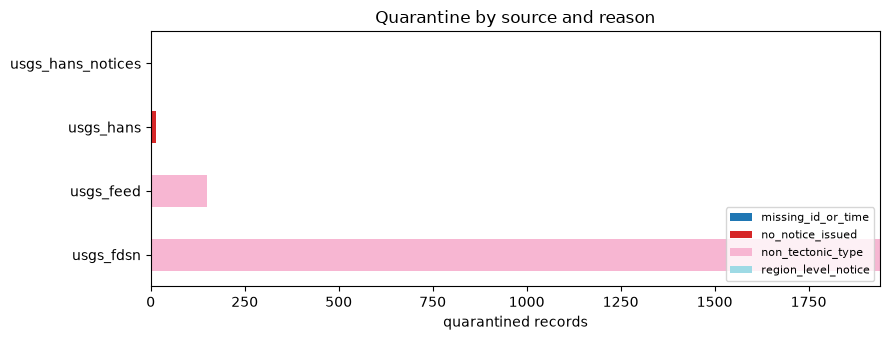

In [16]:
pivot = reasons.pivot_table(index="source_id", columns="reason", values="records", aggfunc="sum", fill_value=0)
fig, ax = plt.subplots(figsize=(9, 3.5))
pivot.plot.barh(stacked=True, ax=ax, colormap="tab20")
ax.set_xlabel("quarantined records")
ax.set_ylabel("")
ax.set_title("Quarantine by source and reason")
ax.legend(fontsize=8, loc="lower right")
save(fig, "quarantine")

## 6. Outliers

Silver flags outliers (it does not drop them) with two methods per numeric field: IQR (1.5 x IQR fences) and z-score. Rates on the newest version of each earthquake.

In [17]:
eq = current["earthquakes"]
flags = [c for c in eq.columns if c.startswith("is_outlier_")]
outlier_rate = pd.DataFrame({
    "flagged": eq[flags].sum(),
    "pct_flagged": 100 * eq[flags].mean(),
}).rename_axis("flag")
display(outlier_rate)
print(f"mag_missing: {100 * eq['mag_missing'].mean():.2f} % of {len(eq)} earthquakes")
eq[["mag", "depth_km", "distance_km"]].describe(percentiles=[.01, .25, .5, .75, .99]).T

,flagged,pct_flagged
flag,,
is_outlier_mag_iqr,11096,3.805278
is_outlier_mag_z,9521,3.265145
is_outlier_depth_iqr,16603,5.693856
is_outlier_depth_z,27162,9.314975


mag_missing: 0.00 % of 291595 earthquakes


,count,mean,std,min,1%,25%,50%,75%,99%,max
mag,291595.0,1.780134,0.597183,1.00,1.00000,1.30,1.71,2.10,3.80000,7.90
depth_km,291595.0,23.677568,41.556576,-3.81,-1.33012,1.34,3.36,20.80,153.50718,584.03
distance_km,291595.0,14.499531,8.781661,0.01,0.84000,5.30,16.02,21.33,29.57000,30.00


network
hv    6540
ak    4196
nc    3492
us    1159
av     762
ci     198
nn     125
uw     105
Name: depth_outliers, dtype: int64

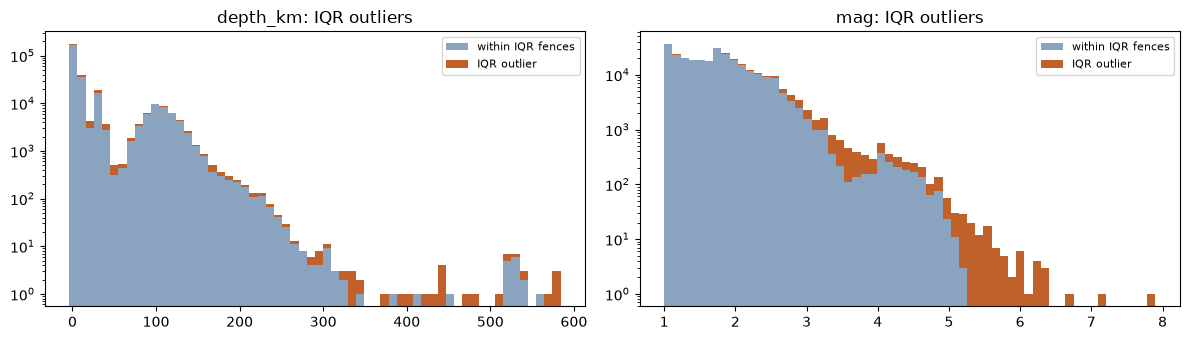

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, col, flag in [(axes[0], "depth_km", "is_outlier_depth_iqr"), (axes[1], "mag", "is_outlier_mag_iqr")]:
    data = eq[[col, flag]].dropna()
    ax.hist([data.loc[~data[flag], col], data.loc[data[flag], col]], bins=60, stacked=True,
            label=["within IQR fences", "IQR outlier"], color=["#8aa4bf", "#c0612b"])
    ax.set_title(f"{col}: IQR outliers")
    ax.set_yscale("log")
    ax.legend(fontsize=8)
save(fig, "outliers")

# Where are the depth outliers? (Alaska slab events, ~30 km Hawaii events)
if len(eq):
    display(eq[eq.is_outlier_depth_iqr].groupby("network", observed=True).size()
            .sort_values(ascending=False).head(8).rename("depth_outliers"))

### 6.1 The outlier fences are relative to each batch

Silver computes the IQR and z-score fences inside each Bronze file (`silver/quality.py` is applied per batch in `silver/transform.py`). A backfill file of one quiet volcano and a feed file of the whole country get different fences, so the same magnitude can be an outlier in one run and normal in another. The table shows, per Bronze file, the smallest flagged value and the largest unflagged value: overlapping ranges confirm it.

In [19]:
def upper_fence(d, col="mag", flag="is_outlier_mag_iqr"):
    # observed upper fence of a batch: smallest HIGH value flagged vs largest value not flagged
    med = d[col].median()
    high_flagged = d.loc[d[flag] & (d[col] > med), col]
    return pd.Series({"rows": len(d), "median_mag": med,
                      "smallest_high_outlier": high_flagged.min(),
                      "largest_normal": d.loc[~d[flag], col].max()})

eq_all = silver["earthquakes"]
mag_fences = (eq_all.groupby("bronze_file").apply(upper_fence)
              .query("rows >= 100").dropna(subset=["smallest_high_outlier"]))
lo, hi = mag_fences.smallest_high_outlier.min(), mag_fences.smallest_high_outlier.max()
print(f"{len(mag_fences)} batches with 100+ earthquakes: the magnitude that starts being an outlier "
      f"goes from M{lo:.2f} to M{hi:.2f}")
example = mag_fences[mag_fences.largest_normal >= lo]
inconsistent = len(example) > 0
if inconsistent:
    print(f"Example: M{lo:.2f} is an outlier in {mag_fences.smallest_high_outlier.idxmin()} "
          f"but values up to M{example.largest_normal.max():.2f} are normal in {example.largest_normal.idxmax()}")
mag_fences.sort_values("smallest_high_outlier").iloc[[0, 1, 2, -3, -2, -1]]

102 batches with 100+ earthquakes: the magnitude that starts being an outlier goes from M1.75 to M5.20
Example: M1.75 is an outlier in usgs_fdsn_20261119_224854.json but values up to M5.10 are normal in usgs_fdsn_20261119_224655.json


,rows,median_mag,smallest_high_outlier,largest_normal
bronze_file,,,,
usgs_fdsn_20261119_224854.json,10057.0,1.12,1.75,1.74
usgs_fdsn_20261119_224858.json,11327.0,1.14,1.87,1.86
usgs_fdsn_20261119_224839.json,131.0,1.23,2.06,1.84
usgs_fdsn_20261119_224728.json,124.0,2.90,5.00,4.40
usgs_fdsn_20261119_224659.json,456.0,4.30,5.20,5.10
usgs_fdsn_20261119_224655.json,163.0,4.40,5.20,5.10


### 6.2 `outlier_rate` with consistent fences (what Gold computes)

To make the KPI consistent across files without changing Silver, Gold recomputes the IQR fences over **all** records instead of per Bronze file. Two consistent options are compared with the Silver flags:

* **global**: one pair of fences for the whole topic. It treats every deep Alaska slab earthquake as an outlier, although they are a real, regular population.
* **per volcano** (chosen): fences over all the records of each volcano (`nearest_vnum`), falling back to the global fences for volcanoes with fewer than 30 earthquakes. Same rule for every file, and each volcano is compared with its own seismicity, as in user story US3.

The Silver flags stay unchanged. (Gold uses `percentile_approx`, so its fences can differ slightly from the exact pandas quantiles.)

In [20]:
def iqr_fences(s: pd.Series, k: float = 1.5):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    return q1 - k * (q3 - q1), q3 + k * (q3 - q1)

MIN_EVENTS = 30
go_rows = []
for col, flag in [("mag", "is_outlier_mag_iqr"), ("depth_km", "is_outlier_depth_iqr")]:
    values = eq[col]
    g_lo, g_hi = iqr_fences(values.dropna())
    is_out_global = (values < g_lo) | (values > g_hi)
    grp = eq.groupby("nearest_vnum")[col]
    q1, q3, size = grp.transform(lambda s: s.quantile(0.25)), grp.transform(lambda s: s.quantile(0.75)), grp.transform("size")
    v_lo = (q1 - 1.5 * (q3 - q1)).where(size >= MIN_EVENTS, g_lo)
    v_hi = (q3 + 1.5 * (q3 - q1)).where(size >= MIN_EVENTS, g_hi)
    is_out_volcano = (values < v_lo) | (values > v_hi)
    go_rows.append({"field": f"earthquakes.{col}",
                    "pct_silver_flags_per_file": 100 * eq[flag].mean(),
                    "pct_global_fences": 100 * is_out_global.mean(),
                    "pct_per_volcano_fences": 100 * is_out_volcano.mean(),
                    "global_fences": f"[{g_lo:.2f}, {g_hi:.2f}]",
                    "differ_from_silver": int((is_out_volcano != eq[flag]).sum())})
outlier_global = pd.DataFrame(go_rows).set_index("field")
print(f"{eq.nearest_vnum.nunique()} volcanoes; {int((eq.groupby('nearest_vnum').size() < MIN_EVENTS).sum())} "
      f"with fewer than {MIN_EVENTS} earthquakes use the global fences")
outlier_global

154 volcanoes; 33 with fewer than 30 earthquakes use the global fences


,pct_silver_flags_per_file,pct_global_fences,pct_per_volcano_fences,global_fences,differ_from_silver
field,,,,,
earthquakes.mag,3.805278,1.811074,3.220220,"[0.10, 3.30]",4446
earthquakes.depth_km,5.693856,16.676555,9.417171,"[-27.85, 49.99]",21265


## 7. Text

The HANS notices (`notices`) are the text corpus of the project; `volcano_updates` is the scraped page. Length is in characters after cleaning (`text_clean`) and of the extracted summary (`summary_clean`).

In [21]:
n = current["notices"]
if len(n):
    n = n.assign(year=n.sent_time.dt.year)
    stats = ["mean", "median", "min", "max"]
    display(n[["text_length", "summary_length", "token_count"]].describe().T)
    display(n.groupby("observatory", observed=True)[["text_length", "summary_length"]].agg(stats).round(0))
    no_summary = missing_mask(n["summary_clean"]).mean() * 100
    print(f"Notices without a summary: {no_summary:.2f} %")

vu = current["volcano_updates"]
if len(vu):
    print("volcano_updates text length:")
    display(vu["text_clean"].str.len().describe().to_frame("chars").T)

,count,mean,std,min,25%,50%,75%,max
text_length,16537.0,2781.408901,2182.934213,85.0,1121.0,2077.0,3842.0,16965.0
summary_length,16537.0,415.795852,346.586221,0.0,215.0,325.0,487.0,6505.0
token_count,16537.0,246.823487,192.515153,5.0,100.0,185.0,342.0,1510.0


text_length                     summary_length                  
                   mean  median  min    max           mean median  min   max
observatory                                                                 
avo              2033.0  1588.0  125  16965          349.0  262.0    0  5240
calvo            1659.0  1852.0  205   3034          831.0  428.0  128  2258
cvo               976.0   905.0  363   5253          354.0  300.0   85  3509
hvo              4188.0  3923.0  143  13198          486.0  411.0    0  6505
nmi              1292.0  1165.0   85   6007          273.0  179.0    0  2391
yvo              2455.0  2471.0  191   6249          393.0  365.0   87   977

Notices without a summary: 0.19 %
volcano_updates text length:


,count,mean,std,min,25%,50%,75%,max
chars,12.0,1708.833333,2356.508003,112.0,213.25,881.0,1433.5,7105.0


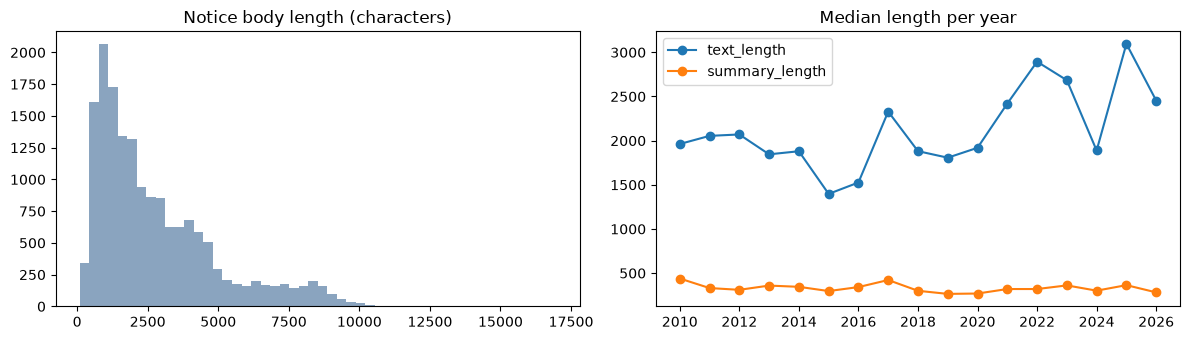

In [22]:
if len(n):
    by_year = n.groupby("year")[["text_length", "summary_length"]].median()
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    axes[0].hist(n.text_length.dropna(), bins=50, color="#8aa4bf")
    axes[0].set_title("Notice body length (characters)")
    by_year.plot(ax=axes[1], marker="o")
    axes[1].set_title("Median length per year")
    axes[1].set_xlabel("")
    save(fig, "text_length")

### 7.3 Language

The Workshop 3 brief suggests a language-distribution KPI for multilingual data. All sources are USGS / Smithsonian publications in English; the check below looks at the non-ASCII characters that do appear.

In [23]:
if len(n):
    text = n["text_clean"].fillna("")
    non_ascii = Counter(ch for t in text for ch in t if ord(ch) > 127)
    share = sum(non_ascii.values()) / max(1, text.str.len().sum()) * 100
    print(f"non-ASCII characters: {share:.3f} % of all characters")
    print("most common:", non_ascii.most_common(12))

non-ASCII characters: 0.106 % of all characters
most common: [('ī', 25397), ('ō', 18054), ('ā', 1843), ('ē', 1067), ('ū', 434), ('ê', 64), ('å', 35), ('œ', 17), ('ä', 11), ('â', 10), ('á', 3), ('é', 3)]


### 7.4 Text encoding

The only non-ASCII characters expected are the Hawaiian vowels with a macron (ā ē ī ō ū; the ʻokina is removed in Silver). Anything else points to text that was decoded twice (UTF-8 read as Latin-1/cp1252, *mojibake*): e.g. `Puʻu ʻŌʻō` becomes `puê u ê åœê å` and `¼ mile` becomes `â1 4 mile`.

In [24]:
EXPECTED = set("āēīōū")
MOJIBAKE = set("âäåœïÃ€™")   # typical bytes of UTF-8 text decoded as cp1252 / Latin-1
if len(n):
    odd = n.text_clean.fillna("").map(lambda t: sorted({ch for ch in t if ord(ch) > 127} - EXPECTED))
    bad = n[odd.map(len) > 0].assign(unexpected=odd)
    bad["kind"] = bad.unexpected.map(lambda cs: "mojibake" if MOJIBAKE & set(cs) else "legitimate accent")
    mojibake = bad[bad.kind == "mojibake"]
    mojibake_rate = 100 * len(mojibake) / len(n)
    print(f"text_length sub-metric pct_encoding_errors = {mojibake_rate:.3f} % of notices")
    print(f"{len(bad)} notices with unexpected non-ASCII characters: {len(mojibake)} mojibake, "
          f"{len(bad) - len(mojibake)} legitimate accents (names such as Társilo, words such as décollement)")
    def context(t, chars):
        i = min(t.find(c) for c in chars if c in t)
        return t[max(0, i - 35): i + 35]
    display(bad.assign(context=[context(t, c) for t, c in zip(bad.text_clean, bad.unexpected)])
            [["sent_time", "observatory", "notice_type", "kind", "unexpected", "context"]]
            .sort_values("kind", ascending=False))

text_length sub-metric pct_encoding_errors = 0.054 % of notices
15 notices with unexpected non-ASCII characters: 9 mojibake, 6 legitimate accents (names such as Társilo, words such as décollement)


,sent_time,observatory,notice_type,kind,unexpected,context
3945,2014-06-25 18:35:06+00:00,avo,VV,mojibake,[â],unerupted magma within the volcanoâ tms condu...
3946,2014-06-25 18:35:06+00:00,avo,VAN,mojibake,[â],unerupted magma within the volcanoâ tms condu...
4048,2014-07-20 18:21:56+00:00,hvo,DU,mojibake,"[ä, å, ê, œ]",kilauea volcano activity summary kä lauea con...
3185,2013-08-21 23:20:21+00:00,avo,IS,mojibake,[â],stly fine ash were collected about â1 4 mile f...
5004,2015-06-03 19:34:04+00:00,hvo,DU,mojibake,"[ä, å, ê, œ]",kilauea volcano activity summary kä lauea vol...
4224,2014-09-11 22:39:02+00:00,avo,IS,mojibake,[â],t 15 km 9 miles east of the volcanoâ tms summi...
4496,2014-12-18 23:32:06+00:00,nmi,WU,mojibake,[â],est information daikoku seamount 21â 1927 12 n...
5484,2015-12-07 20:05:38+00:00,hvo,DU,mojibake,"[ä, å, ê, œ]",this report on the status of kä lauea volcanic...
5485,2015-12-06 21:54:05+00:00,hvo,DU,mojibake,"[ä, å, ê, ï, œ]",this report on the status of kä lauea volcanic...
12325,2023-02-22 18:47:06+00:00,avo,VV,legitimate accent,[á],sgs mcoombs usgs gov 907 786 7497 társilo giro...


## 8. Timeliness

Bronze writes a file only when the source content changed, so fewer files than scheduled runs is **not** necessarily a failure. The measure is therefore *hours with a new Bronze file per day* (a backfill that writes 200 files in one hour counts once), compared with the nominal schedule in `config/sources.yaml` capped at 24 (the `bronze_ingestion` DAG runs hourly). Freshness is the age of the newest file per source.

In [25]:
cfg = yaml.safe_load((ROOT / "config" / "sources.yaml").read_text())
PER_DAY = {"0 * * * *": 24, "@hourly": 24, "*/15 * * * *": 24, "0 */6 * * *": 4, "@daily": 1, "@monthly": 1 / 30}
schedule = {s["source_id"]: s.get("schedule") for s in cfg["sources"] if s.get("enabled", True)}

files = pd.DataFrame({"file": [p.name for p in BRONZE.glob("*.json")]})
files = files.join(files.file.str.extract(BRONZE_NAME)).dropna(subset=["source"])
files["stamp"] = pd.to_datetime(files.stamp, format="%Y%m%d_%H%M%S", utc=True)
files["day"], files["hour"] = files.stamp.dt.floor("D"), files.stamp.dt.floor("h")

per_day = files.groupby(["source", "day"]).agg(files=("file", "size"), hours_with_file=("hour", "nunique")).reset_index()
per_day["expected_per_day"] = per_day.source.map(schedule).map(PER_DAY)
per_day["pct_of_expected"] = (100 * per_day.hours_with_file / per_day.expected_per_day).clip(upper=100)
per_day["partial_day"] = per_day.day == MEASURED_AT.floor("D")
per_day.sort_values(["source", "day"])

,source,day,files,hours_with_file,expected_per_day,pct_of_expected,partial_day
0,gvp_eruptions,2026-11-17 00:00:00+00:00,1,1,0.033333,100.000000,False
1,gvp_volcanoes,2026-11-17 00:00:00+00:00,1,1,0.033333,100.000000,False
2,usgs_fdsn,2026-11-19 00:00:00+00:00,169,2,1.000000,100.000000,True
3,usgs_feed,2026-11-17 00:00:00+00:00,2,1,24.000000,4.166667,False
4,usgs_feed,2026-11-19 00:00:00+00:00,2,2,24.000000,8.333333,True
5,usgs_hans,2026-11-17 00:00:00+00:00,1,1,24.000000,4.166667,False
6,usgs_hans,2026-11-19 00:00:00+00:00,2,2,24.000000,8.333333,True
7,usgs_hans_notices,2026-11-19 00:00:00+00:00,206,2,24.000000,8.333333,True
8,usgs_hans_volcanoes,2026-11-19 00:00:00+00:00,1,1,0.033333,100.000000,True
9,usgs_volcano_updates,2026-11-17 00:00:00+00:00,1,1,24.000000,4.166667,False


In [26]:
freshness = files.groupby("source").stamp.max().rename("last_bronze_file").to_frame()
freshness["hours_since"] = ((MEASURED_AT - freshness.last_bronze_file).dt.total_seconds() / 3600).round(1)
freshness["schedule"] = freshness.index.map(schedule)
freshness["files_with_rows"] = freshness.index.map(
    pd.concat([df["bronze_file"] for df in [*silver.values(), quarantine] if len(df)]).drop_duplicates()
    .pipe(source_of).value_counts()).fillna(0).astype(int)
freshness["bronze_files"] = files.groupby("source").size()
freshness.sort_values("hours_since")

,last_bronze_file,hours_since,schedule,files_with_rows,bronze_files
source,,,,,
usgs_feed,2026-11-19 23:00:02+00:00,0.5,*/15 * * * *,3,4
usgs_fdsn,2026-11-19 23:00:02+00:00,0.5,@daily,165,169
usgs_hans_notices,2026-11-19 23:00:02+00:00,0.5,0 * * * *,204,206
usgs_hans,2026-11-19 23:00:02+00:00,0.5,0 * * * *,3,3
usgs_hans_volcanoes,2026-11-19 22:21:40+00:00,1.1,@monthly,0,1
usgs_volcano_updates,2026-11-19 22:21:40+00:00,1.1,@hourly,2,2
gvp_eruptions,2026-11-17 01:33:08+00:00,69.9,@monthly,1,1
gvp_volcanoes,2026-11-17 01:32:57+00:00,69.9,@monthly,1,1


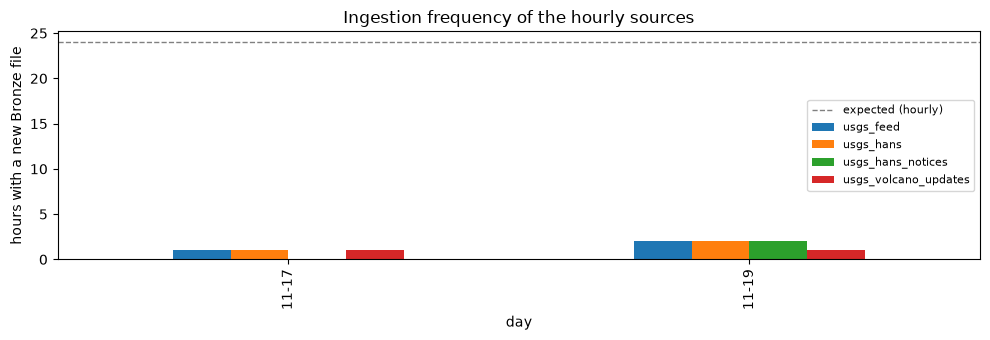

In [27]:
hourly = per_day[per_day.expected_per_day >= 24]
if len(hourly):
    pv = hourly.pivot_table(index="day", columns="source", values="hours_with_file", fill_value=0)
    pv.index = pv.index.strftime("%m-%d")
    fig, ax = plt.subplots(figsize=(10, 3.5))
    pv.plot.bar(ax=ax)
    ax.axhline(24, color="grey", ls="--", lw=1, label="expected (hourly)")
    ax.set_ylabel("hours with a new Bronze file")
    ax.set_title("Ingestion frequency of the hourly sources")
    ax.legend(fontsize=8)
    save(fig, "ingestion_frequency")

## 9. Findings summary

The table is built from the numbers above, so it stays in sync with the data. It is the source of the *Data Quality Findings* section of the report and of the justification of each governance KPI.

In [28]:
def pct(field):
    r = null_rate[null_rate.field == field]
    return float(r.pct_missing.iloc[0]) if len(r) else float("nan")

def q(reason):
    return int(reasons.loc[reasons.reason == reason, "records"].sum())

def out_pct(field):
    if field not in outlier_global.index:
        return "n/a"
    r = outlier_global.loc[field]
    return (f"{r.pct_per_volcano_fences:.1f} % per volcano (Silver per file {r.pct_silver_flags_per_file:.1f} %, "
            f"global {r.pct_global_fences:.1f} %)")

has_notices = len(current["notices"]) > 0
eq_u = uniqueness.loc["earthquakes"] if "earthquakes" in uniqueness.index else None
F = []
def finding(field, issue, frequency, handling, monitored_by, breakdown=""):
    F.append({"field": field, "issue": issue, "frequency": frequency, "handling": handling,
              "monitored_by": monitored_by, "gold_breakdown": breakdown})

# Completeness
finding("eruptions.vei", "missing values", f"{pct('eruptions.vei'):.1f} %", "flag vei_missing, not imputed", "null_rate", "eruptions.vei")
finding("notices.alert_level", "missing values (VONA notices carry only the colour code)", f"{pct('notices.alert_level'):.1f} %",
        "kept; colour code available", "null_rate", "notices.alert_level")
finding("notices.region", "missing values (region-wide notices)", f"{pct('notices.region'):.1f} %", "is_region_wide flag", "null_rate", "notices.region")
finding("alert_notices.latitude/longitude", "missing coordinates", f"{pct('alert_notices.latitude'):.1f} %", "flag coords_missing",
        "null_rate", "alert_notices.latitude")
finding("lineage columns", "gaps in bronze_file / bronze_sha256 / processed_utc",
        "none" if lineage_gaps.empty else f"{len(lineage_gaps)} fields", "required by the Silver writer", "null_rate", "<topic>.bronze_file")
# Uniqueness
finding("earthquakes", "real revisions: USGS changed a value of an event already stored",
        f"{int(eq_u.real_revisions)} rows ({eq_u.pct_real_revisions:.3f} %)" if eq_u is not None else "n/a",
        "kept in Silver; Gold keeps the newest version (latest())", "duplicate_rate", "after dedup: pct_real_revisions")
finding("earthquakes", "same event re-written with another content_hash although no value changed: "
        "the hash depends on the source format (usgs_feed vs usgs_fdsn)",
        f"{int(eq_u.same_value_copies - eq_u.exact_copies)} rows" if eq_u is not None else "n/a",
        "Gold uses latest(), so counts are not affected; proposed Silver fix: hash the normalized values "
        "or accept a new version only when updated_time increases", "duplicate_rate", "after dedup: pct_same_value_copies")
finding("earthquakes", "exact copies: the dedup index keeps only the last hash per id, so feed -> FDSN -> feed "
        "re-admits the first hash",
        f"{int(eq_u.exact_copies)} rows ({eq_u.pct_exact_copies:.3f} %)" if eq_u is not None else "n/a",
        "pipeline bug (silver/state.py) reported to Part 1; detected by this KPI" if eq_u is not None and eq_u.exact_copies
        else "dedup index in _state/; KPI kept as a preventive control", "duplicate_rate", "after dedup: pct_exact_copies")
finding("usgs_fdsn (Bronze)", "same event returned by overlapping radial queries of neighbouring volcanoes",
        f"{fdsn_repeated:,} of {fdsn_total:,} records ({100 * fdsn_repeated / max(1, fdsn_total):.1f} %)",
        "removed by the Silver dedup index", "duplicate_rate", "before dedup: usgs_fdsn")
finding("notices.notice_identifier", "one identifier shared by an activity notice (VAN) and its aviation version (VV)",
        f"{len(shared)} identifiers", "key = identifier + notice type, both kept", "duplicate_rate", "after dedup: exact copies stays 0")
finding("Bronze files", "files that added no row to Silver (all records already seen or out of scope)",
        f"{int(funnel.files_without_rows.sum())} of {int(funnel.files.sum())} files", "dedup index + scope filter",
        "duplicate_rate", "before dedup")
# Validity
finding("Silver files", "files whose schema differs from the contract",
        f"{int((~schema_files.conforms).sum())} of {len(schema_files)} files", "schemas.enforce() before writing",
        "schema_compliance", "topic")
finding("usgs_feed / usgs_fdsn", "non-tectonic events (quarry blasts, explosions)", f"{q('non_tectonic_type'):,} records",
        "quarantine non_tectonic_type", "quarantine_rate", "category business_rule")
finding("usgs_hans", "volcano without notice / region-level notice", f"{q('no_notice_issued') + q('region_level_notice')} records",
        "quarantine (by design)", "quarantine_rate", "category business_rule")
finding("usgs_hans_notices", "notice without identifier or sent time", f"{q('missing_id_or_time')} records",
        "quarantine missing_id_or_time", "quarantine_rate", "category source_defect")
finding("quarantine", "HANS reference file quarantined as unknown_source (pipeline bug)", f"{q('unknown_source')} records",
        "fixed 2026-11-19" + ("; not present in this run" if q("unknown_source") == 0 else ""),
        "quarantine_rate", "category pipeline_error")
# Accuracy
finding("earthquakes.depth_km", "outliers (IQR)", out_pct("earthquakes.depth_km"),
        "flagged, not removed (real deep / slab events); 27 % in the small W2 sample", "outlier_rate", "earthquakes.depth_km")
finding("earthquakes.mag", "outliers (IQR)", out_pct("earthquakes.mag"), "flagged, not removed", "outlier_rate", "earthquakes.mag")
finding("earthquakes.is_outlier_*", "Silver fences computed per Bronze file, not on the whole topic",
        "inconsistent across batches" if inconsistent else "consistent in this data",
        "Gold recomputes the rate with per-volcano fences over all records; Silver flags unchanged", "outlier_rate", "per-volcano fences")
# Consistency
finding("notices.text_length", "long, uneven bodies (boilerplate removed in Part 1)",
        f"median {current['notices'].text_length.median():.0f} chars" if has_notices else "n/a",
        "footer/boilerplate removal, summary extraction", "text_length", "observatory, year")
finding("notices.text_clean", "encoding errors (mojibake, double-decoded UTF-8)",
        f"{len(mojibake)} notices ({mojibake_rate:.3f} %)" if has_notices else "n/a",
        "not fixed yet; proposed re-decoding in the Silver text step", "text_length", "sub-metric pct_encoding_errors")
finding("notices.text_clean", "single language (English); only Hawaiian vowels and a few accented names",
        f"{share:.3f} % non-ASCII characters" if has_notices else "n/a",
        "language_distribution KPI excluded (not applicable)", "text_length", "documented only")
# Timeliness
finding("Bronze files (hourly sources)", "runs without a new file: Bronze writes only when the source changed",
        "see section 8", "measured as hours with a new file per day, not files per run", "ingestion_frequency", "source, day")
finding("all sources", "age of the newest Bronze file", f"max {freshness.hours_since.max():.1f} h (monthly GVP catalogue)",
        "expected age depends on the schedule in sources.yaml", "freshness", "source")

findings = pd.DataFrame(F)
TYPE = {"null_rate": "quality KPI", "duplicate_rate": "quality KPI", "schema_compliance": "quality KPI",
        "quarantine_rate": "quality KPI", "outlier_rate": "quality KPI", "text_length": "quality KPI",
        "volume": "operational metric", "freshness": "operational metric", "ingestion_frequency": "operational metric"}
findings["indicator_type"] = findings.monitored_by.map(TYPE)
findings.index = [f"F{i:02d}" for i in range(1, len(findings) + 1)]
findings

,field,issue,frequency,handling,monitored_by,gold_breakdown,indicator_type
F01,eruptions.vei,missing values,37.5 %,"flag vei_missing, not imputed",null_rate,eruptions.vei,quality KPI
F02,notices.alert_level,missing values (VONA notices carry only the co...,7.9 %,kept; colour code available,null_rate,notices.alert_level,quality KPI
F03,notices.region,missing values (region-wide notices),11.4 %,is_region_wide flag,null_rate,notices.region,quality KPI
F04,alert_notices.latitude/longitude,missing coordinates,7.1 %,flag coords_missing,null_rate,alert_notices.latitude,quality KPI
F05,lineage columns,gaps in bronze_file / bronze_sha256 / processe...,none,required by the Silver writer,null_rate,<topic>.bronze_file,quality KPI
F06,earthquakes,real revisions: USGS changed a value of an eve...,20 rows (0.007 %),kept in Silver; Gold keeps the newest version ...,duplicate_rate,after dedup: pct_real_revisions,quality KPI
F07,earthquakes,same event re-written with another content_has...,371 rows,"Gold uses latest(), so counts are not affected...",duplicate_rate,after dedup: pct_same_value_copies,quality KPI
F08,earthquakes,exact copies: the dedup index keeps only the l...,278 rows (0.095 %),pipeline bug (silver/state.py) reported to Par...,duplicate_rate,after dedup: pct_exact_copies,quality KPI
F09,usgs_fdsn (Bronze),same event returned by overlapping radial quer...,"72,914 of 368,464 records (19.8 %)",removed by the Silver dedup index,duplicate_rate,before dedup: usgs_fdsn,quality KPI
F10,notices.notice_identifier,one identifier shared by an activity notice (V...,706 identifiers,"key = identifier + notice type, both kept",duplicate_rate,after dedup: exact copies stays 0,quality KPI


### 9.1 Indicator catalogue

One row per indicator, with the findings it monitors (ids from the table above). Every indicator has at least one finding, and every finding is monitored by exactly one indicator.

In [29]:
CATALOGUE = [
    ("null_rate", "Completeness", "% of null, blank or empty values per field (newest version of each record)"),
    ("duplicate_rate", "Uniqueness", "% duplicates before dedup (Bronze FDSN) and after dedup (exact copies, same-value copies, real revisions)"),
    ("schema_compliance", "Validity (structure)", "% of Silver files whose columns and types match silver/schemas.py"),
    ("quarantine_rate", "Validity (business rules)", "% of processed records sent to quarantine, by source; reasons and category as breakdown"),
    ("outlier_rate", "Accuracy / plausibility", "% of records outside IQR fences computed per volcano over all its records (global fences below 30 events)"),
    ("text_length", "Consistency", "mean / median / min / max characters per observatory and year; sub-metric % encoding errors"),
    ("volume", "-", "records per topic, total and per week"),
    ("freshness", "Timeliness", "hours since the newest Bronze file, per source"),
    ("ingestion_frequency", "Timeliness", "hours with a new Bronze file per day vs the schedule, per source"),
]
indicators = pd.DataFrame(CATALOGUE, columns=["indicator", "dama_dimension", "definition"]).set_index("indicator")
indicators.insert(0, "type", indicators.index.map(TYPE))
indicators["findings"] = [", ".join(findings.index[findings.monitored_by == k]) or "context for the other rates"
                          for k in indicators.index]
lang_ids = ", ".join(findings.index[findings.issue.str.startswith("single language")])
indicators.loc["language_distribution"] = ["excluded", "-", "not applicable: single-language corpus (section 7.3)", lang_ids]
indicators

,type,dama_dimension,definition,findings
indicator,,,,
null_rate,quality KPI,Completeness,"% of null, blank or empty values per field (ne...","F01, F02, F03, F04, F05"
duplicate_rate,quality KPI,Uniqueness,% duplicates before dedup (Bronze FDSN) and af...,"F06, F07, F08, F09, F10, F11"
schema_compliance,quality KPI,Validity (structure),% of Silver files whose columns and types matc...,F12
quarantine_rate,quality KPI,Validity (business rules),"% of processed records sent to quarantine, by ...","F13, F14, F15, F16"
outlier_rate,quality KPI,Accuracy / plausibility,% of records outside IQR fences computed per v...,"F17, F18, F19"
text_length,quality KPI,Consistency,mean / median / min / max characters per obser...,"F20, F21, F22"
volume,operational metric,-,"records per topic, total and per week",context for the other rates
freshness,operational metric,Timeliness,"hours since the newest Bronze file, per source",F24
ingestion_frequency,operational metric,Timeliness,hours with a new Bronze file per day vs the sc...,F23
